In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11


In [3]:
df = pd.read_csv("/content/customer_churn_cleaned_1100_rows.csv")

df["Signup_Date"] = pd.to_datetime(df["Signup_Date"], errors="coerce")
df["Last_Login"] = pd.to_datetime(df["Last_Login"], errors="coerce")
df["Churn_Date"] = pd.to_datetime(df["Churn_Date"], errors="coerce")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())


Rows: 1100
Columns: 32


,Customer_ID,Customer_Name,Gender,Age,City,State,Signup_Date,Last_Login,Tenure,Contract_Type,...,Customer_Service_Rating,Device_Type,Referral_Source,Churn,Churn_Date,Churn_Reason,Customer_Notes,Data_Source,Signup_Year,Signup_Month
0,cus_0249,Ananya Rao,Male,38,Warangal,Telangana,2026-07-11,2026-08-27,1,Monthly,...,2,Mobile,Friend,0,2026-01-23,Not Churned,No Notes,CRM,2026,7
1,cus_0106,Riya Kapoor,Male,49,Tirupati,Andhra Pradesh,2024-08-26,2026-08-22,24,Two-Year,...,4,Android Phone,Friend,0,2026-01-23,Not Churned,customer happy with service,Mobile App,2024,8
2,cus_0197,Suresh Babu,Female,26,Delhi,Delhi,2025-12-24,2026-01-23,1,Monthly,...,5,Android Phone,Google,0,2026-01-23,Not Churned,moved to competitor,Mobile App,2025,12
3,cus-0891,Sneha Patel,Female,55,Delhi,Delhi,2025-12-24,2026-12-24,12,Monthly,...,3,iPhone,Google,0,2026-01-23,Not Churned,No Notes,Unknown,2025,12
4,cus-0333,Amit Shah,Male,39,Karimnagar,Telangana,2026-07-14,2026-08-27,12,Monthly,...,2,Android Phone,Google,0,2026-01-23,Not Churned,customer happy with service,Unknown,2026,7


In [4]:

print("Total missing values:", df.isna().sum().sum())
print("Duplicate Customer IDs:", df["Customer_ID"].duplicated().sum())
print("Overall churn rate:", round(df["Churn"].mean() * 100, 2), "%")


Total missing values: 0
Duplicate Customer IDs: 0
Overall churn rate: 20.64 %


## Visualization 1 — Overall Churn Rate

**Business question:** What percentage of customers have churned?

This is the headline KPI for the entire churn analysis.


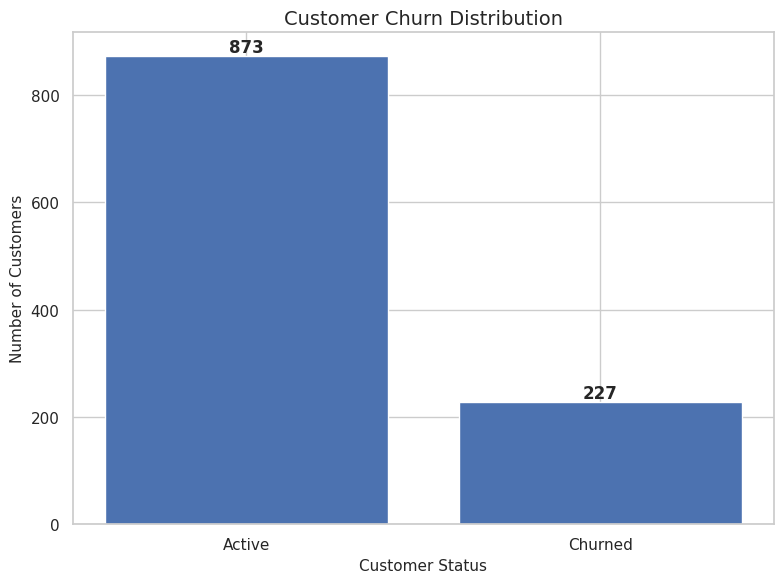

Overall Churn Rate: 20.64%


In [5]:
churn_counts = df["Churn"].value_counts().sort_index()

labels = ["Active", "Churned"]
values = [
    churn_counts.get(0, 0),
    churn_counts.get(1, 0)
]

plt.figure(figsize=(8, 6))

bars = plt.bar(labels, values)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

print(f"Overall Churn Rate: {df['Churn'].mean() * 100:.2f}%")


## Visualization 2 — Churn Rate by Contract Type

**Business question:** Which contract structure is associated with higher customer churn?

A rate comparison is more useful than simply comparing customer counts.


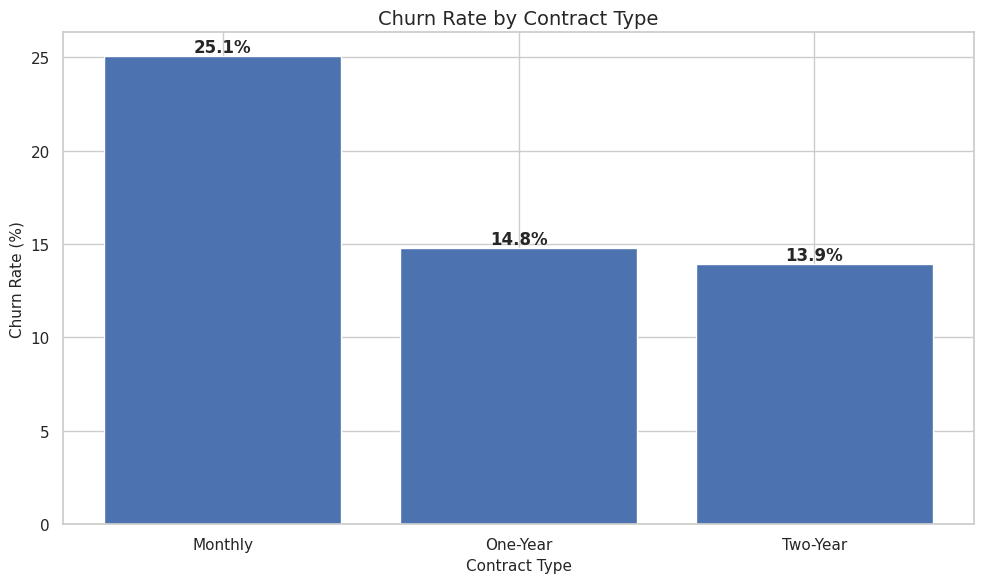

In [6]:
contract_churn = (
    df.groupby("Contract_Type")["Churn"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    contract_churn.index,
    contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

for bar, value in zip(bars, contract_churn.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()


## Visualization 3 — Revenue at Risk by Subscription Plan

**Business question:** Which subscription plans contain the largest amount of monthly revenue from churned customers?

This connects churn directly to potential revenue exposure.


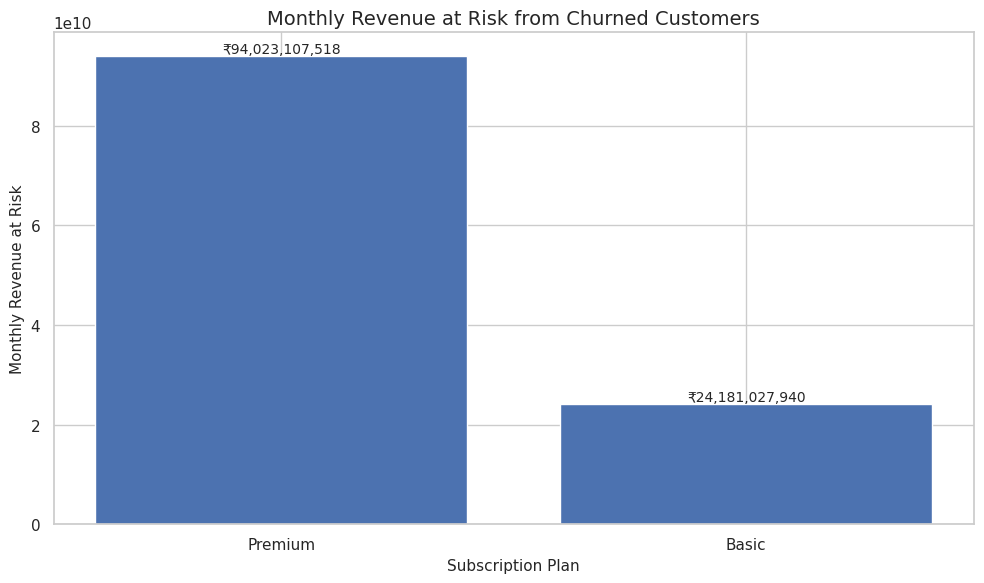

In [7]:
revenue_risk = (
    df[df["Churn"] == 1]
    .groupby("Subscription_Plan")["Monthly_Charges"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    revenue_risk.index,
    revenue_risk.values
)

plt.title("Monthly Revenue at Risk from Churned Customers")
plt.xlabel("Subscription Plan")
plt.ylabel("Monthly Revenue at Risk")

for bar, value in zip(bars, revenue_risk.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"₹{value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()


## Visualization 4 — Satisfaction vs Churn

**Business question:** Does customer satisfaction appear to be associated with churn?

The chart compares churn rates across satisfaction levels.


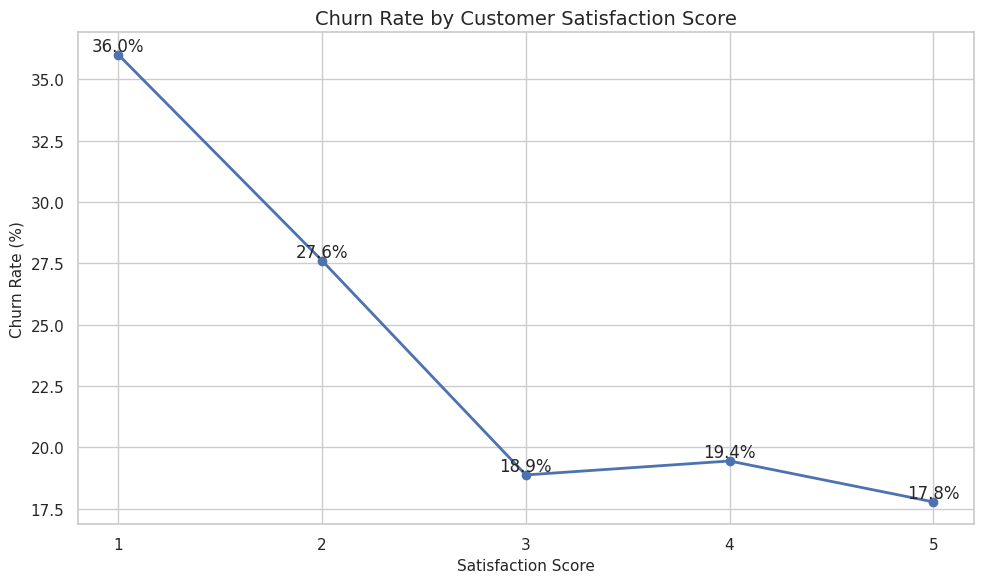

In [8]:

satisfaction_churn = (
    df.groupby("Satisfaction_Score")["Churn"]
      .mean()
      .mul(100)
      .sort_index()
)

plt.figure(figsize=(10, 6))

plt.plot(
    satisfaction_churn.index,
    satisfaction_churn.values,
    marker="o",
    linewidth=2
)

plt.title("Churn Rate by Customer Satisfaction Score")
plt.xlabel("Satisfaction Score")
plt.ylabel("Churn Rate (%)")
plt.xticks(sorted(satisfaction_churn.index))

for x, y in zip(
    satisfaction_churn.index,
    satisfaction_churn.values
):
    plt.text(
        x,
        y,
        f"{y:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


## Visualization 5 — Support Calls and Churn

**Business question:** Is heavy customer-support interaction associated with higher churn?

This visualization looks for a behavioral risk pattern.


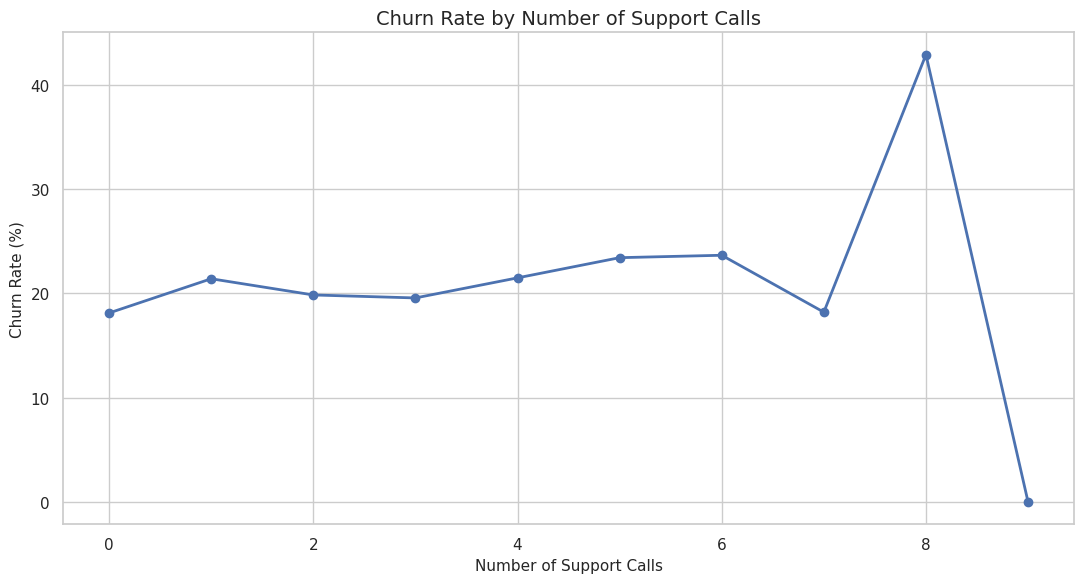

In [9]:

support_churn = (
    df.groupby("Support_Calls")["Churn"]
      .mean()
      .mul(100)
      .sort_index()
)

plt.figure(figsize=(11, 6))

plt.plot(
    support_churn.index,
    support_churn.values,
    marker="o",
    linewidth=2
)

plt.title("Churn Rate by Number of Support Calls")
plt.xlabel("Number of Support Calls")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()


## Visualization 6 — Complaints vs Churn

**Business question:** How does the number of complaints relate to customer churn?

This helps identify whether repeated service issues may be an important churn signal.


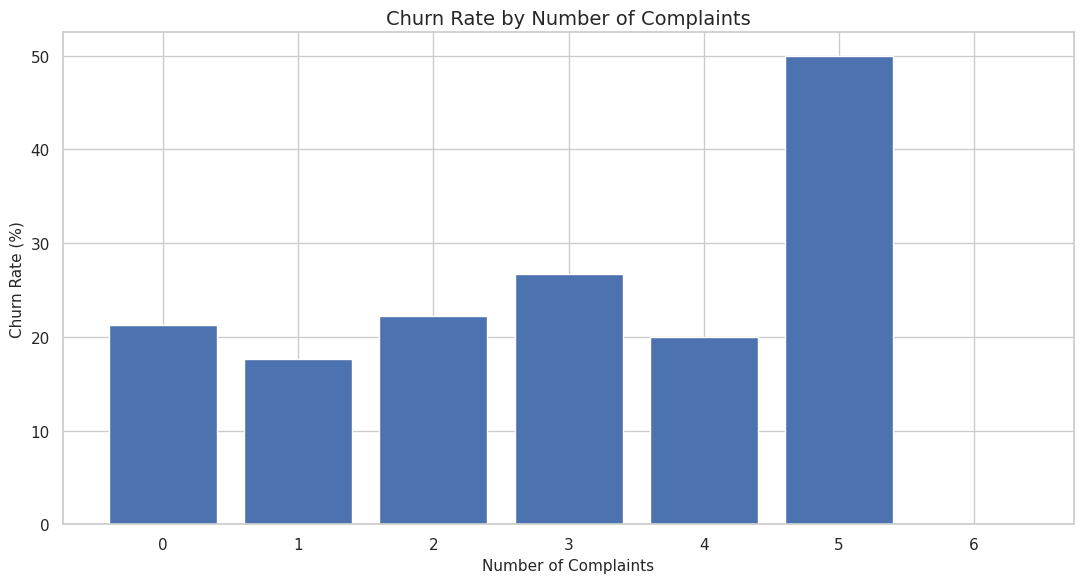

In [10]:

complaint_churn = (
    df.groupby("Complaints")["Churn"]
      .mean()
      .mul(100)
      .sort_index()
)

plt.figure(figsize=(11, 6))

plt.bar(
    complaint_churn.index.astype(str),
    complaint_churn.values
)

plt.title("Churn Rate by Number of Complaints")
plt.xlabel("Number of Complaints")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()


## Visualization 7 — Monthly Charges vs Churn

**Business question:** Are higher-paying customers showing a different churn pattern?

A boxplot reveals the distribution of monthly charges for active and churned customers.


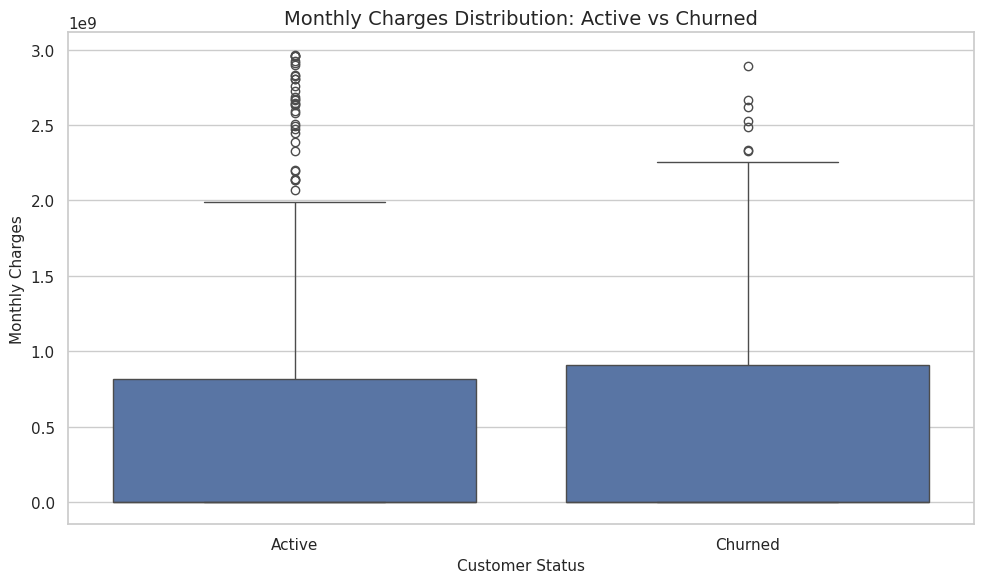

In [11]:

plot_df = df.copy()

plot_df["Customer_Status"] = plot_df["Churn"].map({
    0: "Active",
    1: "Churned"
})

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=plot_df,
    x="Customer_Status",
    y="Monthly_Charges"
)

plt.title("Monthly Charges Distribution: Active vs Churned")
plt.xlabel("Customer Status")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()


## Visualization 8 — Customer Engagement vs Churn

**Business question:** Does login frequency differ between active and churned customers?

This can reveal whether disengagement is an early churn signal.


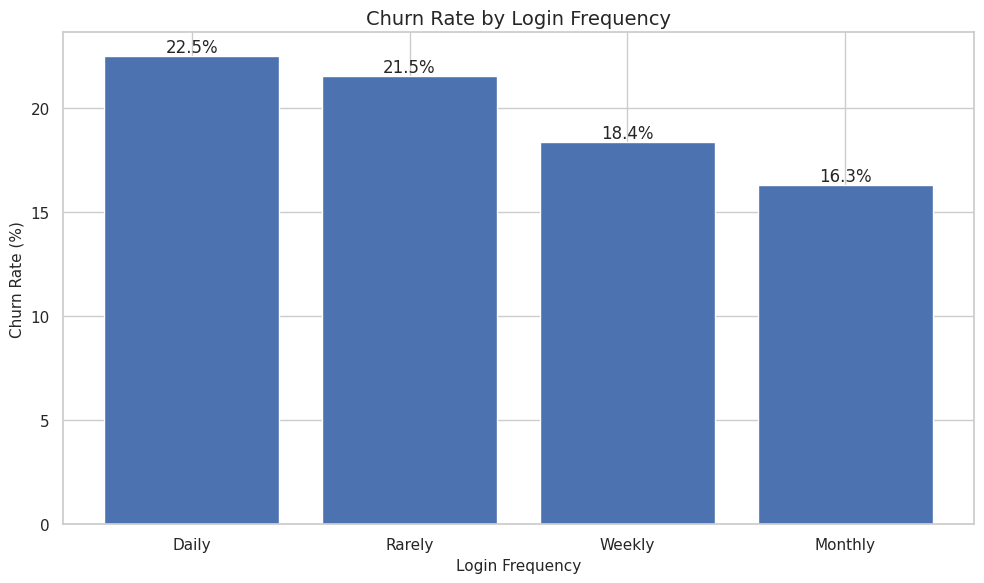

In [12]:

login_churn = (
    df.groupby("Login_Frequency")["Churn"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    login_churn.index,
    login_churn.values
)

plt.title("Churn Rate by Login Frequency")
plt.xlabel("Login Frequency")
plt.ylabel("Churn Rate (%)")

for bar, value in zip(bars, login_churn.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


## Visualization 9 — Churn Rate by State

**Business question:** Are there geographic differences in customer churn?

This helps identify regions that may require targeted retention analysis.


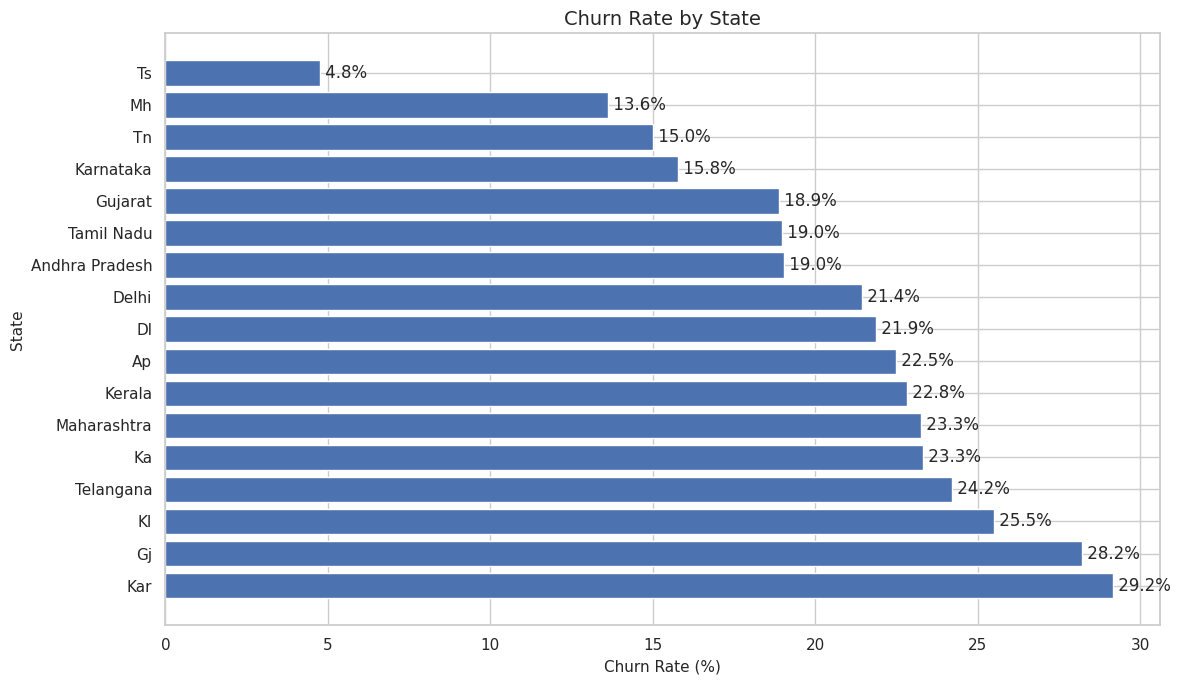

In [13]:

state_churn = (
    df.groupby("State")["Churn"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    state_churn.index,
    state_churn.values
)

plt.title("Churn Rate by State")
plt.xlabel("Churn Rate (%)")
plt.ylabel("State")

for bar, value in zip(bars, state_churn.values):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {value:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()


## Visualization 10 — Churn Reasons

**Business question:** Why are customers leaving?

This is one of the most actionable visualizations because it connects churn volume with potential retention actions.


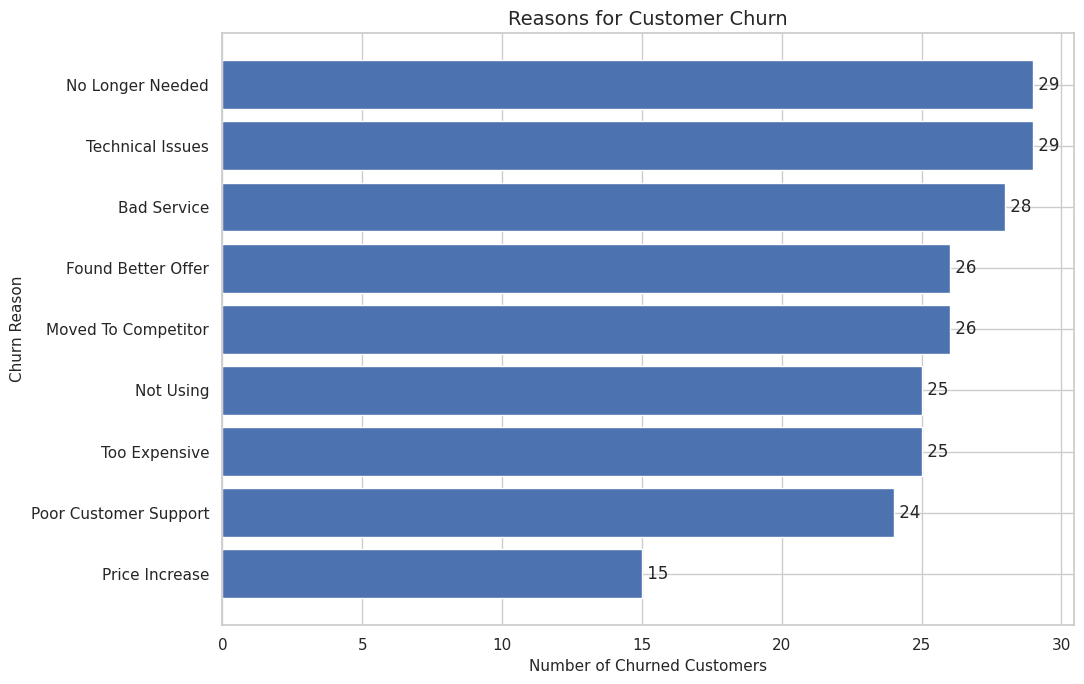

In [14]:

reason_counts = (
    df[df["Churn"] == 1]["Churn_Reason"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(11, 7))

bars = plt.barh(
    reason_counts.index,
    reason_counts.values
)

plt.title("Reasons for Customer Churn")
plt.xlabel("Number of Churned Customers")
plt.ylabel("Churn Reason")

for bar, value in zip(bars, reason_counts.values):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {value:,}",
        va="center"
    )

plt.tight_layout()
plt.show()


# Bonus Analysis — High-Risk Customer Profile

This section combines several business variables to identify the characteristics of churned customers.

It is not a machine-learning prediction. It is a descriptive business profile.


In [15]:

churned = df[df["Churn"] == 1]

profile = pd.DataFrame({
    "Metric": [
        "Churn Rate",
        "Average Age",
        "Average Tenure",
        "Average Monthly Charges",
        "Average Support Calls",
        "Average Complaints",
        "Average Satisfaction",
        "Average Service Rating"
    ],
    "Value": [
        df["Churn"].mean() * 100,
        churned["Age"].mean(),
        churned["Tenure"].mean(),
        churned["Monthly_Charges"].mean(),
        churned["Support_Calls"].mean(),
        churned["Complaints"].mean(),
        churned["Satisfaction_Score"].mean(),
        churned["Customer_Service_Rating"].mean()
    ]
})

display(profile.round(2))


,Metric,Value
0,Churn Rate,2.064000e+01
1,Average Age,3.507000e+01
2,Average Tenure,1.279000e+01
3,Average Monthly Charges,5.207231e+08
4,Average Support Calls,2.920000e+00
5,Average Complaints,1.150000e+00
6,Average Satisfaction,3.140000e+00
7,Average Service Rating,3.240000e+00


# 10 Key Business Insights

The next cells automatically calculate the strongest descriptive findings from the cleaned dataset.

Important: these are **observed associations**, not proof that one variable causes churn.


In [16]:

overall_churn = df["Churn"].mean() * 100

contract_rates = df.groupby("Contract_Type")["Churn"].mean() * 100
highest_contract = contract_rates.idxmax()
highest_contract_rate = contract_rates.max()

plan_revenue = (
    df[df["Churn"] == 1]
    .groupby("Subscription_Plan")["Monthly_Charges"]
    .sum()
)
highest_revenue_plan = plan_revenue.idxmax()
highest_revenue_value = plan_revenue.max()

sat_rates = df.groupby("Satisfaction_Score")["Churn"].mean() * 100
lowest_sat_score = sat_rates.idxmax()
lowest_sat_rate = sat_rates.max()

support_rates = df.groupby("Support_Calls")["Churn"].mean() * 100
highest_support_calls = support_rates.idxmax()
highest_support_rate = support_rates.max()

complaint_rates = df.groupby("Complaints")["Churn"].mean() * 100
highest_complaints = complaint_rates.idxmax()
highest_complaint_rate = complaint_rates.max()

login_rates = df.groupby("Login_Frequency")["Churn"].mean() * 100
highest_login_risk = login_rates.idxmax()
highest_login_rate = login_rates.max()

state_rates = df.groupby("State")["Churn"].mean() * 100
highest_state = state_rates.idxmax()
highest_state_rate = state_rates.max()

reason_counts = df.loc[df["Churn"] == 1, "Churn_Reason"].value_counts()
top_reason = reason_counts.idxmax()
top_reason_count = reason_counts.max()

print("1. Overall churn rate")
print(f"   {overall_churn:.2f}% of customers have churned.")

print("\n2. Contract risk")
print(f"   {highest_contract} has the highest observed churn rate at {highest_contract_rate:.2f}%.")

print("\n3. Revenue exposure")
print(f"   {highest_revenue_plan} has the largest monthly revenue exposure among churned customers: ₹{highest_revenue_value:,.0f}.")

print("\n4. Satisfaction")
print(f"   Satisfaction score {lowest_sat_score} has the highest observed churn rate at {lowest_sat_rate:.2f}%.")

print("\n5. Support interaction")
print(f"   Customers with {highest_support_calls} support calls show the highest observed churn rate at {highest_support_rate:.2f}%.")

print("\n6. Complaints")
print(f"   Customers with {highest_complaints} complaints show the highest observed churn rate at {highest_complaint_rate:.2f}%.")

print("\n7. Customer engagement")
print(f"   {highest_login_risk} login frequency has the highest observed churn rate at {highest_login_rate:.2f}%.")

print("\n8. Geographic pattern")
print(f"   {highest_state} has the highest observed churn rate at {highest_state_rate:.2f}%.")

print("\n9. Main churn reason")
print(f"   '{top_reason}' is the most common recorded churn reason, with {top_reason_count:,} customers.")

print("\n10. Revenue + churn")
print(f"   Total monthly revenue represented by churned customers: ₹{df.loc[df['Churn'] == 1, 'Monthly_Charges'].sum():,.0f}.")


1. Overall churn rate
   20.64% of customers have churned.

2. Contract risk
   Monthly has the highest observed churn rate at 25.08%.

3. Revenue exposure
   Premium has the largest monthly revenue exposure among churned customers: ₹94,023,107,518.

4. Satisfaction
   Satisfaction score 1 has the highest observed churn rate at 36.00%.

5. Support interaction
   Customers with 8 support calls show the highest observed churn rate at 42.86%.

6. Complaints
   Customers with 5 complaints show the highest observed churn rate at 50.00%.

7. Customer engagement
   Daily login frequency has the highest observed churn rate at 22.50%.

8. Geographic pattern
   Kar has the highest observed churn rate at 29.17%.

9. Main churn reason
   'Technical Issues' is the most common recorded churn reason, with 29 customers.

10. Revenue + churn
   Total monthly revenue represented by churned customers: ₹118,204,135,458.


# Final Churn KPI Summary

In [17]:


total_customers = len(df)
churned_customers = int(df["Churn"].sum())
active_customers = total_customers - churned_customers

total_monthly_revenue = df["Monthly_Charges"].sum()
churned_monthly_revenue = df.loc[df["Churn"] == 1, "Monthly_Charges"].sum()

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Customers",
        "Active Customers",
        "Churned Customers",
        "Overall Churn Rate",
        "Total Monthly Revenue",
        "Monthly Revenue from Churned Customers",
        "Average Monthly Charge",
        "Average Customer Tenure"
    ],
    "Value": [
        total_customers,
        active_customers,
        churned_customers,
        f"{overall_churn:.2f}%",
        f"₹{total_monthly_revenue:,.0f}",
        f"₹{churned_monthly_revenue:,.0f}",
        f"₹{df['Monthly_Charges'].mean():,.2f}",
        f"{df['Tenure'].mean():.1f} months"
    ]
})

display(kpi_summary)


,KPI,Value
0,Total Customers,1100
1,Active Customers,873
2,Churned Customers,227
3,Overall Churn Rate,20.64%
4,Total Monthly Revenue,"₹515,892,735,165"
5,Monthly Revenue from Churned Customers,"₹118,204,135,458"
6,Average Monthly Charge,"₹468,993,395.60"
7,Average Customer Tenure,13.6 months


In [18]:

analysis_path = "/content/customer_churn_analysis_ready.csv"
df.to_csv(analysis_path, index=False)

print("Analysis-ready dataset:", analysis_path)


Analysis-ready dataset: /content/customer_churn_analysis_ready.csv
